# 02 Safety and Deployment Analysis

Separates verified exposure-aligned safety evidence from incident counts and supplier metrics.
It never treats vehicle deliveries, systems shipped, incidents, miles, and trips as interchangeable units.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Execute with project root as the working directory."
pd.set_option("display.max_colwidth", 120)


In [2]:
safety=pd.read_csv(ROOT/"data/reporting/safety_indicators.csv")
deployment=pd.read_csv(ROOT/"data/reporting/deployment_metrics.csv")
safety[["company_name","indicator_name","value","unit","exposure_basis","status","limitation"]]

,company_name,indicator_name,value,unit,exposure_basis,status,limitation
0,Waymo,Rider-only miles analyzed,56700000.0,mile,Waymo ODD matched benchmark,Verified,Exposure denominator available for Waymo only
1,Waymo,Any-injury vehicle-to-vehicle intersection crash rate reduction,96.0,percent,Matched human benchmark; lower CI,Verified,Company-authored research and selected ODDs
2,Waymo,Airbag-deployment crash rate reduction,91.0,percent,Matched human benchmark; lower CI,Verified,Not a cross-company rate
3,Tesla,NHTSA Level 2 incident records,NaN,record,NHTSA SGO archive,Available but not redistributed,Raw totals cannot be normalized because FSD/Autopilot exposure denominator is unavailable
4,Waymo,NHTSA ADS incident records,NaN,record,NHTSA SGO archive,Available but not redistributed,Reporting threshold and report versions differ from Level 2
5,NVIDIA,Direct operator safety exposure,NaN,not applicable,Platform provider,Not comparable,NVIDIA does not operate a single comparable public fleet
6,Mobileye,Direct operator safety exposure,NaN,not applicable,OEM supplier,Not comparable,Mobileye technology spans many OEMs and automation levels


In [3]:
deployment[["company_name","metric_date","metric_name","metric_value","unit","period_type","limitation"]]

,company_name,metric_date,metric_name,metric_value,unit,period_type,limitation
0,Waymo,2025-01-31,Rider-only autonomous miles,56700000,mile,Cumulative,Matched safety analysis exposure through January 2025
1,Waymo,2025-03-25,Fully autonomous miles,50000000,mile,Cumulative minimum,Rounded lower-bound claim; superseded by 56.7m dataset for safety analysis
2,Waymo,2025-03-25,Paid trips per week,200000,trip/week,Point-in-time minimum,Company-defined paid trips
3,Waymo,2025-05-05,Paid trips per week,250000,trip/week,Point-in-time minimum,Company-defined paid trips
4,Waymo,2025-05-05,Operating vehicles,1500,vehicle,Point-in-time minimum,"More than 1,500; stored as lower bound"
5,Tesla,2024-12-31,Consumer vehicle deliveries,1789226,vehicle/year,Annual,Vehicle deliveries are not autonomous driving exposure
6,Mobileye,2024-12-28,EyeQ and SuperVision systems shipped,29000000,system/year,Annual,Mixed product tiers and automation levels
7,Mobileye,2024-12-28,Cumulative vehicles with Mobileye technology,200000000,vehicle,Cumulative minimum,More than 200 million; mixed generations
8,California program total,2024-11-30,California AV test miles with safety driver,3945171,mile/year,Annual program total,All permit holders combined; not company-specific
9,California program total,2024-11-30,California fully autonomous test miles,552895,mile/year,Annual program total,All permit holders combined; not company-specific


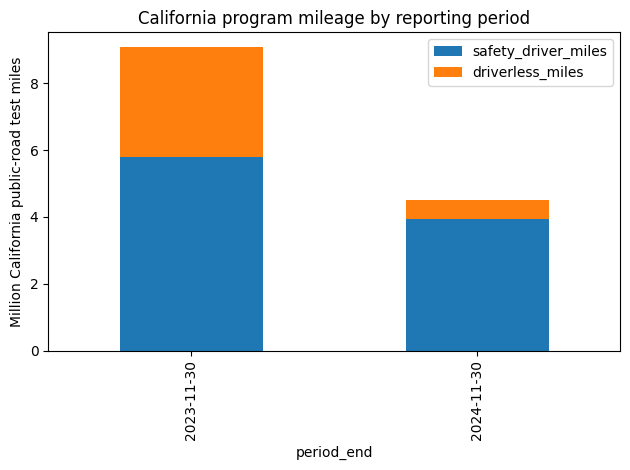

In [4]:
ca=pd.read_csv(ROOT/"data/cleaned/fact_disengagement.csv")
ax=ca.set_index("period_end")[["safety_driver_miles","driverless_miles"]].div(1e6).plot(kind="bar",stacked=True)
ax.set_ylabel("Million California public-road test miles")
ax.set_title("California program mileage by reporting period")
plt.tight_layout()
plt.show()

**Key warning:** NHTSA ADS and Level 2 reports have different thresholds, California reporting omits major testing categories, and public system-level mileage denominators are unavailable for Tesla. NVIDIA and Mobileye are evaluated as platforms or suppliers, not as homogeneous fleets.